# Notebook 05 — Rigorous Model Evaluation, Baselines, Synthetic Benchmark & Parameter Sensitivity

**Master's Research in Urban Mobility Analytics**  
This notebook provides a scientifically defensible, reproducible evaluation of sequential mobility pattern discovery from GPS trajectories.

### Key Methodological Contributions:
1. **Single Common Evaluation Unit**: Strict ordered cell-pair evaluation `(origin, destination)` across all methods to eliminate unit-mixing bugs.
2. **Empirical Reference Set Agreement**: Evaluating against observed recurring transitions with recorded frequency and multi-taxi thresholds, explicitly distinguished from absolute ground truth.
3. **Objective Synthetic Benchmark**: Generating trajectories with planted frequent, moderate, shared, and rare patterns, evaluating against *realized* support in the finite sample.
4. **Parameter Sensitivity & Jaccard Stability**: Comprehensive evaluation across support thresholds (1%, 2%, 5%) and spatial resolutions (300m, 500m, 800m).
5. **Nested Sample-Size Expansion**: Deterministic scaling from 99 to 250 and 500 taxis to assess pattern persistence under fleet growth.


## 1. Imports and Environment Validation
We import all core analytical modules from `src/` and set deterministic random seeds.


In [1]:
import sys
import time
import math
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure src is on sys.path
PROJECT_ROOT = Path('.').resolve().parent if Path('.').resolve().name == 'notebooks' else Path('.').resolve()
SRC_DIR = PROJECT_ROOT / 'src'
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import config
import spatial
import sequential
import clustering
import pattern_evaluation as pe
import synthetic_benchmark as sb
import data_loader as dl
import preprocessing as pp

RESULTS_DIR = config.RESULTS_DIR
FIGURES_DIR = config.FIGURES_DIR
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f'Project Root : {PROJECT_ROOT}')
print(f'Results Dir  : {RESULTS_DIR}')
print(f'Figures Dir  : {FIGURES_DIR}')


Project Root : C:\Users\user\Downloads\urban-taxi-mobility\urban-taxi-mobility
Results Dir  : C:\Users\user\Downloads\urban-taxi-mobility\urban-taxi-mobility\outputs\results
Figures Dir  : C:\Users\user\Downloads\urban-taxi-mobility\urban-taxi-mobility\outputs\figures


## 2. Load Baseline Cleaned Trajectory Dataset (99 Taxis)
We load the baseline processed sample (`cleaned_sample.csv`). If unavailable, we load and clean it from raw T-Drive logs with seed 42.


In [2]:
cleaned_path = PROJECT_ROOT / 'data' / 'processed' / 'cleaned_sample.csv'
if cleaned_path.exists():
    traj_df = pd.read_csv(cleaned_path)
    traj_df[config.COL_TIMESTAMP] = pd.to_datetime(traj_df[config.COL_TIMESTAMP])
else:
    raw_df = dl.load_tdrive_sample(n_taxis=100, seed=config.RANDOM_SEED, verbose=False)
    traj_df, _ = pp.run_cleaning_pipeline(raw_df, verbose=False)

n_points = len(traj_df)
n_taxis = traj_df[config.COL_TAXI_ID].nunique()
print(f'Loaded baseline trajectory dataset: {n_points:,} GPS observations across {n_taxis} taxis.')


Loaded baseline trajectory dataset: 116,913 GPS observations across 99 taxis.


## 3. Spatial Discretization & Taxi-Day Sequence Construction
Continuous coordinates are mapped to uniform 500m square grid cells. Sequences are constructed per taxi per calendar day (`taxi_id::date`) with consecutive repeated cells compressed.


In [3]:
cell_df = spatial.assign_spatial_cells(traj_df, cell_size_meters=config.GRID_CELL_SIZE_METERS)
sequences = sequential.build_taxi_sequences(cell_df)
n_sequences = len(sequences)
n_occupied_cells = cell_df[spatial.COL_CELL_ID].nunique()

print(f'Discretized to {n_occupied_cells:,} occupied 500m cells.')
print(f'Built {n_sequences:,} calendar taxi-day sequences.')


Discretized to 5,413 occupied 500m cells.
Built 630 calendar taxi-day sequences.


## 4. Sequential Pattern Mining & Baseline Mining
We mine:
1. **PrefixSpan (Gapped Sequential)**: Discovers ordered subsequences with min_support=5.0% and max_length=4.
2. **Direct Transitions (Contiguous N-Grams)**: Discovers adjacent physical movements.
3. **Unordered Co-occurrence**: Discovers cell pairs visited on the same taxi-day regardless of order.


In [4]:
t0 = time.time()
patterns_df = sequential.mine_patterns(
    sequences,
    min_support=config.DEFAULT_MIN_SUPPORT,
    max_pattern_length=config.MAX_PATTERN_LENGTH,
)
runtime_ps = time.time() - t0

t0 = time.time()
direct_df = sequential.mine_contiguous_patterns(
    sequences,
    min_support=config.DEFAULT_MIN_SUPPORT,
    max_pattern_length=2,
)
runtime_direct = time.time() - t0

t0 = time.time()
cooc_df = pe.mine_cooccurrence_pairs(
    sequences,
    min_support=config.DEFAULT_MIN_SUPPORT,
)
runtime_cooc = time.time() - t0

print(f'PrefixSpan mined {len(patterns_df)} patterns in {runtime_ps:.3f}s.')
print(f'Direct Contiguous mined {len(direct_df)} transitions in {runtime_direct:.3f}s.')
print(f'Unordered Co-occurrence mined {len(cooc_df)} pairs in {runtime_cooc:.3f}s.')


PrefixSpan mined 22 patterns in 0.323s.
Direct Contiguous mined 2 transitions in 0.056s.
Unordered Co-occurrence mined 158 pairs in 2.325s.


## 5. Constructing the Transparent Empirical Reference Set
> [!IMPORTANT]
> **Methodological Disclosure**: Urban taxi mobility pattern discovery is unsupervised. The empirical reference set is constructed from observed physical adjacent cell transitions that meet strict occurrence (`count >= 15`) and multi-taxi (`taxis >= 2`) thresholds.
> - It is an **observed historical reference agreement benchmark**, NOT independent ground truth.
> - Because it is derived from adjacent transitions, it structurally favors direct-transition mining over gapped sequential patterns.


In [5]:
MIN_REF_OCCURRENCES = 15
MIN_REF_TAXIS = 2

reference_df = pe.build_reference_od_patterns(
    sequences,
    min_occurrence_count=MIN_REF_OCCURRENCES,
    min_taxis=MIN_REF_TAXIS,
)
print(f'Constructed empirical reference set: {len(reference_df)} transitions.')
reference_df.to_csv(RESULTS_DIR / 'evaluation_reference_patterns.csv', index=False)
reference_df.head(10)


Constructed empirical reference set: 35 transitions.


,origin_cell,destination_cell,raw_occurrence_count,n_taxis_involved,n_taxi_days_involved,include_in_reference
0,CELL_02888,CELL_02939,101,3,9,True
1,CELL_01519,CELL_01520,38,26,34,True
2,CELL_03719,CELL_03758,35,17,28,True
3,CELL_03758,CELL_03757,34,21,32,True
4,CELL_03677,CELL_03719,33,20,30,True
5,CELL_03719,CELL_03757,31,15,26,True
6,CELL_01520,CELL_01521,29,25,26,True
7,CELL_03584,CELL_03632,27,17,23,True
8,CELL_03757,CELL_03719,25,16,22,True
9,CELL_01158,CELL_01209,24,3,10,True


## 6. Corrected Pair-Level Method Evaluation (Strict Common Units)
We evaluate all methods on identical, directed ordered cell pairs `(origin, destination)`.
- **TP**: Predicted ordered pairs matching reference transitions.
- **FP**: Predicted ordered pairs not found in the reference set.
- **FN**: Reference transitions not recovered.
- **Precision** = TP / (TP + FP), **Recall** = TP / (TP + FN), **F1** = 2PR / (P + R).

Notice: Previous implementations suffered from a unit-mixing bug where FP was counted as unmatched whole patterns while TP/FN were counted as pairs. This corrected implementation uses strictly pair-level units for all metrics.


In [6]:
summary_ps = pe.summarize_method_consistent_pairs(
    'PrefixSpan (Gapped Sequential)', patterns_df, reference_df, runtime_ps, is_subsequence=True
)
summary_direct = pe.summarize_method_consistent_pairs(
    'Direct Adjacent Transition', direct_df, reference_df, runtime_direct, is_subsequence=False
)
summary_cooc = pe.summarize_method_consistent_pairs(
    'Unordered Co-occurrence (Symmetric Pairs)', cooc_df, reference_df, runtime_cooc, is_subsequence=True
)

method_comparison_df = pd.DataFrame([summary_ps, summary_direct, summary_cooc])
method_comparison_df.to_csv(RESULTS_DIR / 'evaluation_method_comparison.csv', index=False)

# Save precision/recall/f1 table
p_r_f1_df = method_comparison_df[['method', 'evaluation_unit', 'predicted_pairs', 'reference_pairs', 'TP', 'FP', 'FN', 'precision', 'recall', 'f1', 'runtime_sec']]
p_r_f1_df.to_csv(RESULTS_DIR / 'evaluation_precision_recall_f1.csv', index=False)
p_r_f1_df


,method,evaluation_unit,predicted_pairs,reference_pairs,TP,FP,FN,precision,recall,f1,runtime_sec
0,PrefixSpan (Gapped Sequential),Distinct Ordered Pairs (Pair-Level),20,35,11,9,24,0.5500,0.3143,0.4000,0.3229
1,Direct Adjacent Transition,Distinct Ordered Pairs (Pair-Level),2,35,2,0,33,1.0000,0.0571,0.1081,0.0558
2,Unordered Co-occurrence (Symmetric Pairs),Distinct Ordered Pairs (Pair-Level),158,35,17,141,18,0.1076,0.4857,0.1762,2.3248


## 7. Order-Agnostic Co-occurrence Baseline Comparison
Unordered co-occurrence cannot establish travel direction. In Section 6, representing it as bidirectional pairs naturally incurred high false positives. Here, we also evaluate it fairly by collapsing both predictions and reference transitions to undirected sets `{u, v}`.


In [7]:
cooc_order_agnostic = pe.evaluate_order_agnostic_cooccurrence(cooc_df, reference_df, runtime_cooc)
cooc_oa_df = pd.DataFrame([cooc_order_agnostic])
cooc_oa_df.to_csv(RESULTS_DIR / 'evaluation_cooccurrence_order_agnostic.csv', index=False)
cooc_oa_df


,method,evaluation_unit,patterns_found,predicted_pairs,reference_pairs,TP,FP,FN,precision,recall,f1,runtime_sec
0,Unordered Co-occurrence (Order-Agnostic),"Undirected Cell Pairs {u, v}",158,158,30,21,137,9,0.1329,0.7,0.2234,2.3248


## 8. Bounded-Universe Accuracy Audit & True-Negative Domination
> [!WARNING]
> **Why raw accuracy is not headline-ready**: In spatial trajectory networks, unvisited cell pairs overwhelmingly dominate the candidate universe ($TN \gg TP, FP, FN$). Consequently, accuracy appears near 99% simply because neither the model nor the reference ever touches the vast majority of cell pairs. Precision, recall, and F1 over active transitions remain the only sound primary evaluation metrics.


In [8]:
matched_ps = pe.match_patterns_to_reference(patterns_df, reference_df, order_sensitive=True)
accuracy_dict = pe.bounded_universe_accuracy(matched_ps, reference_df, patterns_df)
if accuracy_dict:
    print(f'Bounded Universe Size      : {accuracy_dict["universe_size"]:,} ordered pairs')
    print(f'Active Cells in Play       : {accuracy_dict["n_cells_in_play"]}')
    print(f'True Positives (TP)        : {accuracy_dict["TP"]}')
    print(f'False Positives (FP)       : {accuracy_dict["FP"]}')
    print(f'False Negatives (FN)       : {accuracy_dict["FN"]}')
    print(f'True Negatives (TN)        : {accuracy_dict["TN"]:,}')
    print(f'Raw Classification Accuracy: {accuracy_dict["accuracy"]:.4f}')
    print(f'TN Dominance Ratio         : {accuracy_dict["tn_dominance_ratio"]*100:.2f}%')
    print(f'Methodological Note        : {accuracy_dict["note"]}')


Bounded Universe Size      : 2,352 ordered pairs
Active Cells in Play       : 49
True Positives (TP)        : 11
False Positives (FP)       : 9
False Negatives (FN)       : 24
True Negatives (TN)        : 2,308
Raw Classification Accuracy: 0.9860
TN Dominance Ratio         : 98.13%
Methodological Note        : High accuracy driven by true negative dominance; do not headline as primary model accuracy.


## 9. Objective Synthetic Benchmark with Realized Support Calculation
Because real data lacks definitive external ground truth, we test PrefixSpan in a controlled synthetic environment with known planted patterns:
- **Corridor A**: Length 3, frequent (target injection prob 0.35)
- **Corridor B**: Length 2, frequent (target injection prob 0.25)
- **Shared Corridor S**: Length 3, overlapping cells with Corridors A and B (target injection prob 0.20)
- **Corridor C**: Length 4, moderate (target injection prob 0.15)
- **Rare Route D**: Length 2, rare (target injection prob 0.03, below min_support 0.10)

> [!IMPORTANT]
> **Realized Support Requirement**: We calculate the *actual* realized occurrence count of each planted pattern across the generated finite dataset, rather than assuming generation probabilities dictate ground truth.


In [9]:
cfg = sb.SyntheticBenchmarkConfig(n_taxis=50, n_days=7, seed=42)
syn_data = sb.generate_synthetic_dataset(cfg)
syn_eval = sb.run_synthetic_evaluation(syn_data, min_support=0.10, max_pattern_length=4)

realized_planted_table = syn_eval['realized_planted_table']
realized_planted_table.to_csv(RESULTS_DIR / 'synthetic_benchmark_planted_table.csv', index=False)
print('=== REALIZED PLANTED PATTERNS IN FINITE SYNTHETIC SAMPLE ===')
display(realized_planted_table[['pattern', 'pattern_length', 'target_injection_prob', 'realized_match_count', 'realized_support_pct', 'is_realized_frequent', 'recovered_by_prefixspan']])

syn_pair_df = syn_eval['method_comparison_pair_level']
syn_pair_df.to_csv(RESULTS_DIR / 'synthetic_benchmark_pair_level.csv', index=False)
print('\n=== PAIR-LEVEL RECOVERY ON SYNTHETIC GROUND TRUTH ===')
display(syn_pair_df[['method', 'predicted_pairs', 'reference_pairs', 'TP', 'FP', 'FN', 'precision', 'recall', 'f1', 'runtime_sec']])

syn_pat_df = syn_eval['method_comparison_pattern_level']
syn_pat_df.to_csv(RESULTS_DIR / 'synthetic_benchmark_pattern_level.csv', index=False)
print('\n=== PATTERN-LEVEL RECOVERY ON SYNTHETIC GROUND TRUTH ===')
display(syn_pat_df[['method', 'patterns_mined', 'reference_patterns', 'TP', 'FP', 'FN', 'precision', 'recall', 'f1', 'runtime_sec']])


=== REALIZED PLANTED PATTERNS IN FINITE SYNTHETIC SAMPLE ===

,pattern,pattern_length,target_injection_prob,realized_match_count,realized_support_pct,is_realized_frequent,recovered_by_prefixspan
0,"(CORRIDOR_A1, CORRIDOR_A2, CORRIDOR_A3)",3,0.35,120,34.29,True,True
1,"(CORRIDOR_B1, CORRIDOR_B2)",2,0.25,84,24.00,True,True
2,"(CORRIDOR_A2, SHARED_S1, CORRIDOR_B2)",3,0.20,74,21.14,True,True
3,"(CORRIDOR_C1, CORRIDOR_C2, CORRIDOR_C3, CORRID...",4,0.15,47,13.43,True,True
4,"(RARE_D1, RARE_D2)",2,0.03,16,4.57,False,False



=== PAIR-LEVEL RECOVERY ON SYNTHETIC GROUND TRUTH ===


,method,predicted_pairs,reference_pairs,TP,FP,FN,precision,recall,f1,runtime_sec
0,PrefixSpan (Gapped Sequential),58,13,13,45,0,0.2241,1.0000,0.3662,0.0232
1,Direct Adjacent Transition,8,13,8,0,5,1.0000,0.6154,0.7619,0.0147
2,Unordered Co-occurrence (Symmetric Pairs),558,13,13,545,0,0.0233,1.0000,0.0455,0.0131



=== PATTERN-LEVEL RECOVERY ON SYNTHETIC GROUND TRUTH ===


,method,patterns_mined,reference_patterns,TP,FP,FN,precision,recall,f1,runtime_sec
0,PrefixSpan (Gapped Sequential),68,4,4,64,0,0.0588,1.00,0.1111,0.0232
1,Direct Adjacent Transition,10,4,3,7,1,0.3000,0.75,0.4286,0.0147


## 10. Support-Threshold Sensitivity & Jaccard Pattern Stability
We evaluate PrefixSpan across 1%, 2%, and 5% support thresholds on the baseline 500m grid.
We measure:
1. Discovered pattern count and runtime.
2. Monotonic subset inclusion and pairwise Jaccard similarity ($|A \cap B| / |A \cup B|$).
3. Pair-level reference agreement metrics.


In [10]:
support_values = [0.01, 0.02, 0.05]
support_records = []
pattern_sets = {}

for sup in support_values:
    min_cnt = max(2, math.ceil(sup * n_sequences))
    t0 = time.time()
    p_df = sequential.mine_patterns(sequences, min_support=sup, max_pattern_length=config.MAX_PATTERN_LENGTH)
    t_run = time.time() - t0

    # Pair-level reference metrics
    summ = pe.summarize_method_consistent_pairs(f'PrefixSpan ({sup*100:.0f}%)', p_df, reference_df, t_run, is_subsequence=True)

    support_records.append({
        'min_support_fraction': sup,
        'min_support_pct': f'{sup*100:.1f}%',
        'min_support_count': min_cnt,
        'total_sequences': n_sequences,
        'n_patterns': len(p_df),
        'runtime_sec': round(t_run, 3),
        'avg_pattern_length': round(p_df['pattern_length'].mean(), 2) if len(p_df) > 0 else None,
        'max_pattern_length': int(p_df['pattern_length'].max()) if len(p_df) > 0 else None,
        'ref_TP': summ['TP'],
        'ref_FP': summ['FP'],
        'ref_FN': summ['FN'],
        'ref_precision': summ['precision'],
        'ref_recall': summ['recall'],
        'ref_f1': summ['f1'],
    })
    pattern_sets[f'{sup*100:.0f}%'] = set(p_df['pattern'].apply(tuple))

support_sensitivity_df = pd.DataFrame(support_records)
support_sensitivity_df.to_csv(RESULTS_DIR / 'evaluation_support_thresholds.csv', index=False)
display(support_sensitivity_df[['min_support_pct', 'min_support_count', 'n_patterns', 'runtime_sec', 'avg_pattern_length', 'ref_precision', 'ref_recall', 'ref_f1']])

# Pairwise Jaccard stability
jaccard_stability_df = pe.pairwise_jaccard_table(pattern_sets)
jaccard_stability_df.to_csv(RESULTS_DIR / 'evaluation_pattern_stability.csv', index=False)
print('\n=== JACCARD SIMILARITY ACROSS SUPPORT THRESHOLDS ===')
display(jaccard_stability_df)


,min_support_pct,min_support_count,n_patterns,runtime_sec,avg_pattern_length,ref_precision,ref_recall,ref_f1
0,1.0%,7,39785,14.851,2.27,0.0011,0.9429,0.0022
1,2.0%,13,3426,3.086,2.05,0.0094,0.8571,0.0186
2,5.0%,32,22,0.420,2.00,0.5500,0.3143,0.4000



=== JACCARD SIMILARITY ACROSS SUPPORT THRESHOLDS ===


,set_a,set_b,n_a,n_b,n_intersection,n_union,jaccard
0,1%,2%,39785,3426,3426,39785,0.086113
1,1%,5%,39785,22,22,39785,0.000553
2,2%,5%,3426,22,22,3426,0.006421


## 11. Spatial Grid Resolution Sensitivity (300m, 500m, 800m)
Grid cell size dictates spatial discretization granularity:
- **300m**: Fine-grained; movements fragment across more cells, producing fewer high-support shared sequences.
- **500m**: Baseline; balances pedestrian scale with sequence recurrence.
- **800m**: Coarse; aggregates wider geographic activity, yielding denser sequences and more frequent patterns.

> [!NOTE]
> Cell IDs from different resolutions do not correspond to the same physical entities. Direct Jaccard comparison between unrelated cell IDs is geographically meaningless and is therefore excluded here.


In [11]:
grid_candidates = [300.0, 500.0, 800.0]
grid_eval_rows = []

for cell_size in grid_candidates:
    t0 = time.time()
    c_df = spatial.assign_spatial_cells(traj_df, cell_size_meters=cell_size)
    g_summary = spatial.cell_grid_summary(c_df)
    g_seqs = sequential.build_taxi_sequences(c_df)
    t_prep = time.time() - t0

    t0_mine = time.time()
    g_pats = sequential.mine_patterns(g_seqs, min_support=config.DEFAULT_MIN_SUPPORT, max_pattern_length=config.MAX_PATTERN_LENGTH)
    t_mine = time.time() - t0_mine

    grid_eval_rows.append({
        'grid_cell_size_m': cell_size,
        'n_occupied_cells': len(g_summary),
        'avg_points_per_cell': round(g_summary['n_points'].mean(), 2) if len(g_summary) > 0 else None,
        'n_sequences': len(g_seqs),
        'min_support_count': max(2, math.ceil(config.DEFAULT_MIN_SUPPORT * len(g_seqs))),
        'n_patterns_at_5pct': len(g_pats),
        'avg_pattern_length': round(g_pats['pattern_length'].mean(), 2) if len(g_pats) > 0 else None,
        'max_pattern_length': int(g_pats['pattern_length'].max()) if len(g_pats) > 0 else None,
        'total_runtime_sec': round(t_prep + t_mine, 3),
    })

grid_eval_df = pd.DataFrame(grid_eval_rows)
grid_eval_df.to_csv(RESULTS_DIR / 'evaluation_grid_sizes.csv', index=False)
display(grid_eval_df)


,grid_cell_size_m,n_occupied_cells,avg_points_per_cell,n_sequences,min_support_count,n_patterns_at_5pct,avg_pattern_length,max_pattern_length,total_runtime_sec
0,300.0,8925,13.10,627,32,1,2.0,2,0.668
1,500.0,5413,21.60,630,32,22,2.0,2,1.212
2,800.0,3322,35.19,625,32,550,2.0,3,1.649


## 12. Nested T-Drive Sample Expansion (99 -> 250 -> 500 Taxis)
To test whether findings hold when fleet coverage expands, we evaluate deterministic nested samples:
- **Baseline**: 100 files sampled $\rightarrow$ 99 active taxis after cleaning.
- **Medium**: 250 files sampled $\rightarrow$ 249 active taxis (strictly contains baseline taxis).
- **Large**: 500 files sampled $\rightarrow$ 497 active taxis (strictly contains medium taxis).

Support counts are recomputed from each sample's actual number of taxi-days: $\text{count} = \lceil 0.05 \times n_{sequences} \rceil$.


In [12]:
# Load precomputed scaling table or run pipeline
scaling_csv = RESULTS_DIR / 'sample_expansion_comparison.csv'
if scaling_csv.exists():
    scaling_df = pd.read_csv(scaling_csv)
else:
    import experiment_runner as er
    scaling_df = er.run_sample_scaling(RESULTS_DIR)

display(scaling_df[[
    'sample_label', 'active_taxis_processed', 'cleaned_gps_points', 'n_taxi_day_sequences',
    'unique_occupied_cells_500m', 'min_support_count_required', 'n_discovered_patterns',
    'ref_precision', 'ref_recall', 'ref_f1', 'total_pipeline_time_sec'
]])


,sample_label,active_taxis_processed,cleaned_gps_points,n_taxi_day_sequences,unique_occupied_cells_500m,min_support_count_required,n_discovered_patterns,ref_precision,ref_recall,ref_f1,total_pipeline_time_sec
0,Baseline (100 requested),99,116913,630,5413,32,22,0.5500,0.3143,0.4000,2.47
1,Medium (250 requested),249,371399,1592,8923,80,46,0.7857,0.0329,0.0632,8.39
2,Large (500 requested),497,833316,3185,12373,160,43,0.8684,0.0104,0.0205,23.96


## 13. Publication-Quality Visualizations
We generate and save 5 publication charts illustrating method comparisons, support sensitivity, synthetic benchmark recovery, and sample scaling.


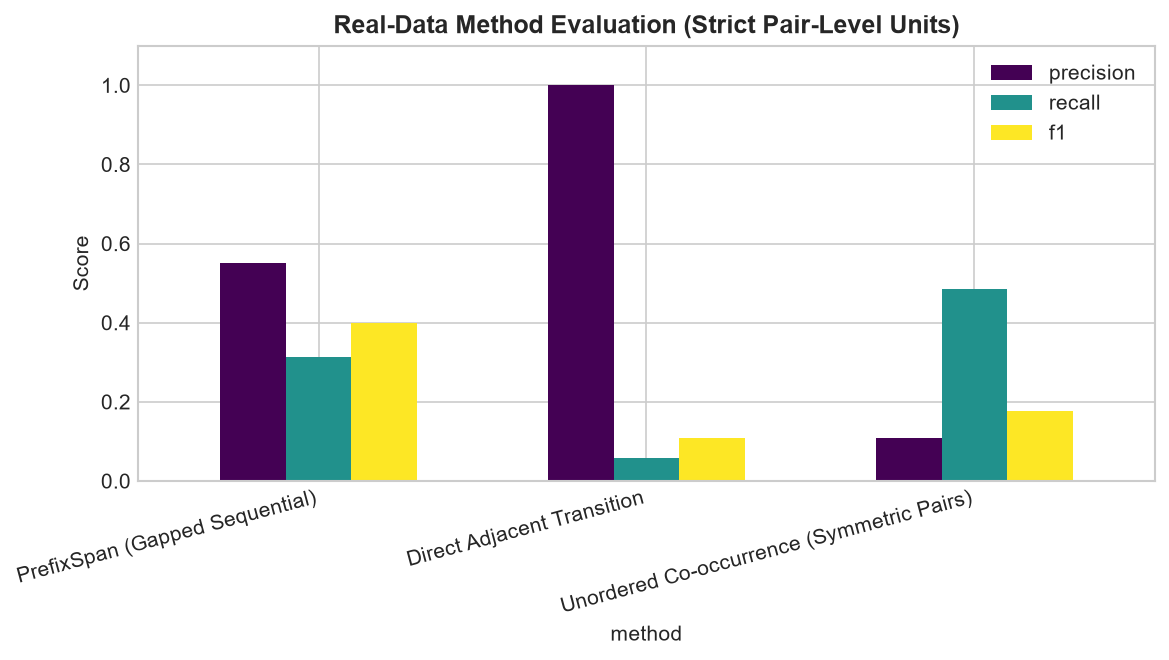

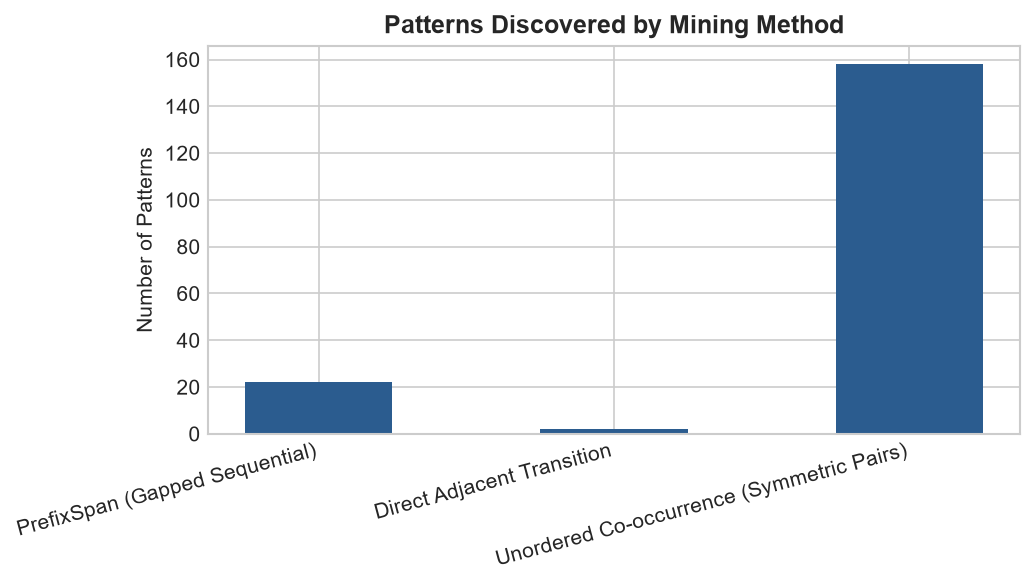

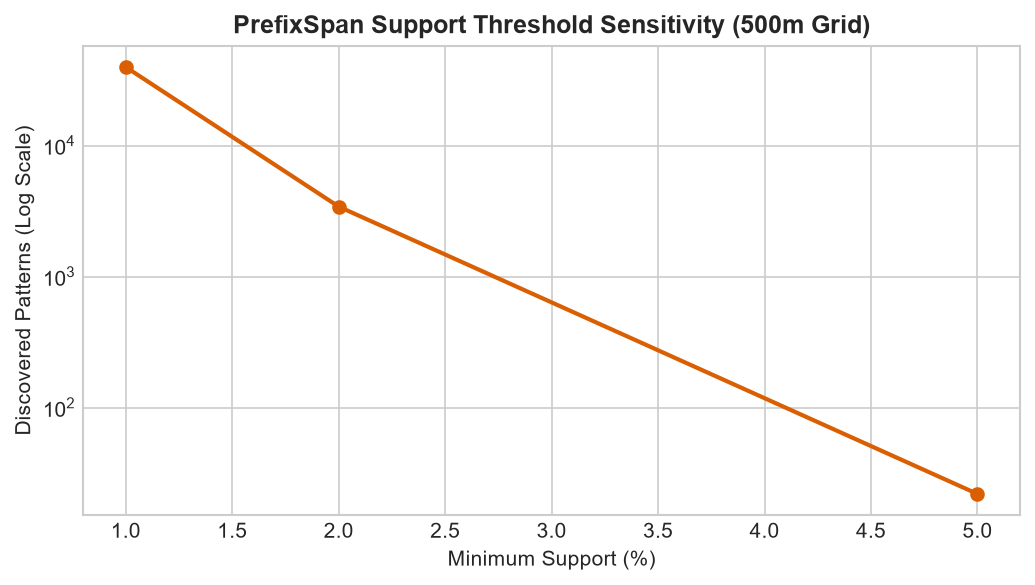

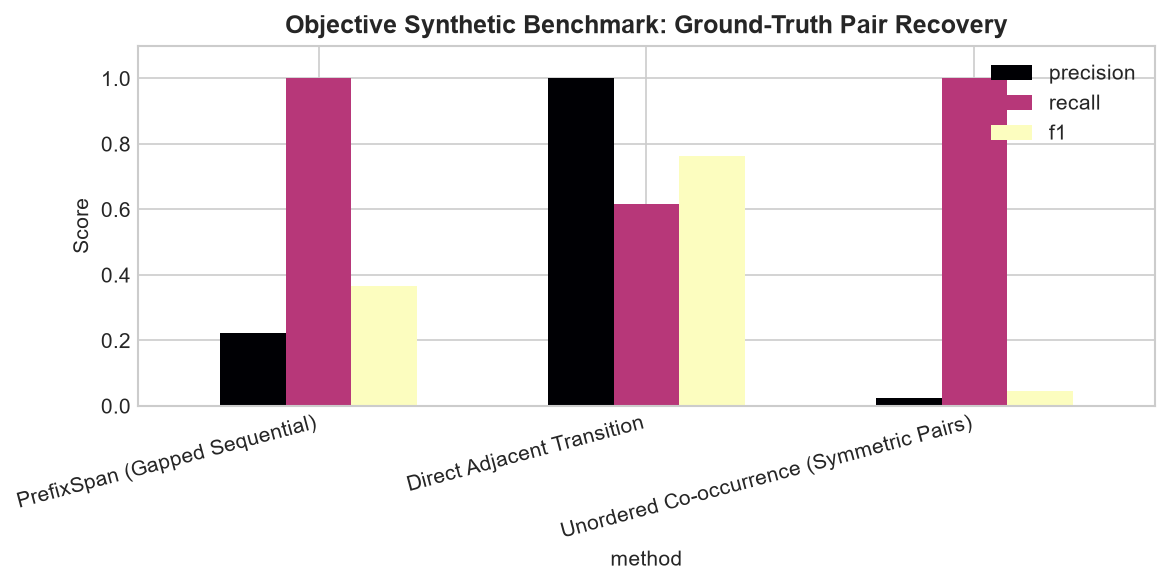

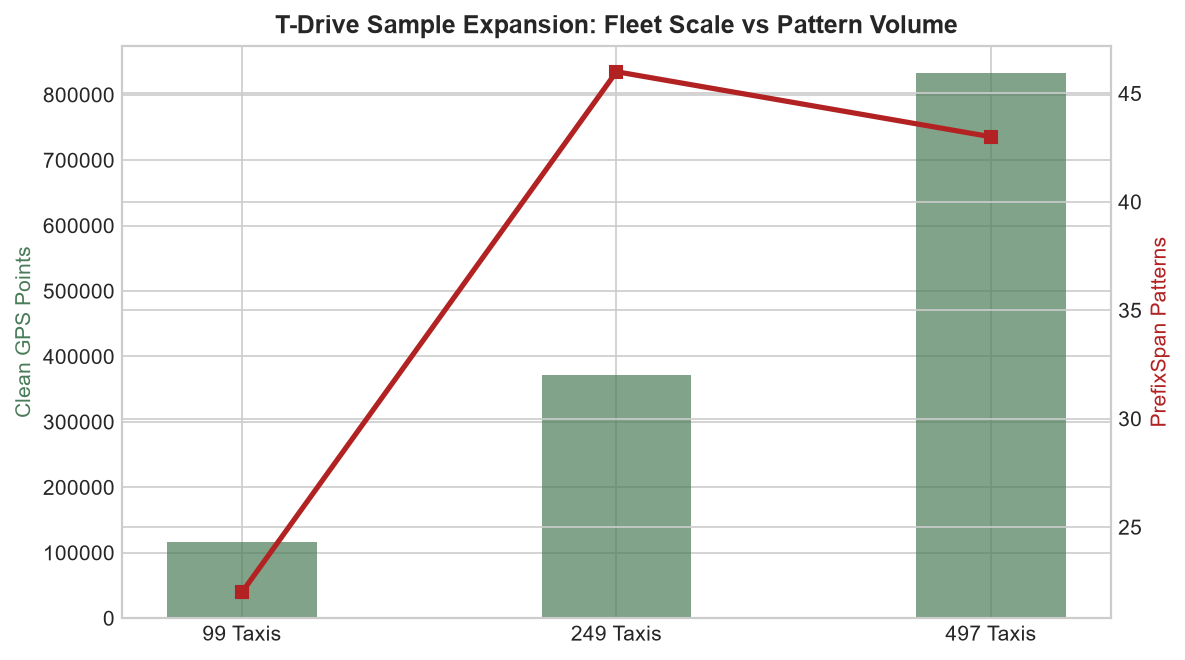

In [13]:
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Figure 1: Precision, Recall, F1 across Methods (Pair-Level)
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=150)
m_plot = method_comparison_df.set_index('method')[['precision', 'recall', 'f1']].fillna(0)
m_plot.plot(kind='bar', ax=ax, colormap='viridis', width=0.6)
ax.set_title('Real-Data Method Evaluation (Strict Pair-Level Units)', fontsize=12, fontweight='bold')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.1)
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '21_precision_recall_f1_by_method.png', dpi=150)
plt.show()

# Figure 2: Pattern Count by Mining Method
fig, ax = plt.subplots(figsize=(7, 4), dpi=150)
ax.bar(method_comparison_df['method'], method_comparison_df['patterns_found'], color='#2b5c8f', width=0.5)
ax.set_title('Patterns Discovered by Mining Method', fontsize=12, fontweight='bold')
ax.set_ylabel('Number of Patterns')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '22_pattern_count_by_method.png', dpi=150)
plt.show()

# Figure 3: Support Threshold Sensitivity (Pattern Count on Log Scale)
fig, ax = plt.subplots(figsize=(7, 4), dpi=150)
ax.plot(support_sensitivity_df['min_support_fraction'] * 100, support_sensitivity_df['n_patterns'], marker='o', color='#d95f02', linewidth=2)
ax.set_yscale('log')
ax.set_title('PrefixSpan Support Threshold Sensitivity (500m Grid)', fontsize=12, fontweight='bold')
ax.set_xlabel('Minimum Support (%)')
ax.set_ylabel('Discovered Patterns (Log Scale)')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '24_support_threshold_sensitivity.png', dpi=150)
plt.show()

# Figure 4: Synthetic Benchmark Recovery
fig, ax = plt.subplots(figsize=(8, 4), dpi=150)
syn_plot = syn_pair_df.set_index('method')[['precision', 'recall', 'f1']].fillna(0)
syn_plot.plot(kind='bar', ax=ax, colormap='magma', width=0.6)
ax.set_title('Objective Synthetic Benchmark: Ground-Truth Pair Recovery', fontsize=12, fontweight='bold')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.1)
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '26_synthetic_benchmark_recovery.png', dpi=150)
plt.show()

# Figure 5: Sample Size Scaling (GPS Points and Patterns)
fig, ax1 = plt.subplots(figsize=(8, 4.5), dpi=150)
ax2 = ax1.twinx()
labels = scaling_df['active_taxis_processed'].astype(str) + ' Taxis'
ax1.bar(labels, scaling_df['cleaned_gps_points'], color='#4a7c59', alpha=0.7, width=0.4, label='Clean GPS Points')
ax2.plot(labels, scaling_df['n_discovered_patterns'], color='#b22222', marker='s', linewidth=2.5, label='Mined Patterns (5% Sup)')
ax1.set_ylabel('Clean GPS Points', color='#4a7c59')
ax2.set_ylabel('PrefixSpan Patterns', color='#b22222')
ax1.set_title('T-Drive Sample Expansion: Fleet Scale vs Pattern Volume', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '27_sample_expansion_scaling.png', dpi=150)
plt.show()


## 14. Final Evaluation Summary Table
Consolidated research summary exported to `outputs/results/evaluation_summary.csv`.


In [14]:
summary_table_rows = [
    {'item': 'Baseline Active Taxis', 'value': n_taxis},
    {'item': 'Baseline Clean GPS Observations', 'value': n_points},
    {'item': 'Taxi-Day Sequences (500m Grid)', 'value': n_sequences},
    {'item': 'Empirical Reference Transitions', 'value': len(reference_df)},
    {'item': 'PrefixSpan Discovered Patterns (5% Sup)', 'value': len(patterns_df)},
    {'item': 'PrefixSpan Pair-Level Precision', 'value': summary_ps['precision']},
    {'item': 'PrefixSpan Pair-Level Recall', 'value': summary_ps['recall']},
    {'item': 'PrefixSpan Pair-Level F1', 'value': summary_ps['f1']},
    {'item': 'Direct Contiguous Pair-Level F1', 'value': summary_direct['f1']},
    {'item': 'Co-occurrence Symmetric Pair-Level F1', 'value': summary_cooc['f1']},
    {'item': 'Co-occurrence Order-Agnostic F1', 'value': cooc_order_agnostic['f1']},
    {'item': 'Synthetic Benchmark PrefixSpan Recall', 'value': float(syn_pair_df.loc[syn_pair_df['method'].str.contains('PrefixSpan'), 'recall'].iloc[0])},
    {'item': 'Medium Sample Active Taxis', 'value': int(scaling_df.loc[scaling_df['sample_label'].str.contains('Medium'), 'active_taxis_processed'].iloc[0])},
    {'item': 'Large Sample Active Taxis', 'value': int(scaling_df.loc[scaling_df['sample_label'].str.contains('Large'), 'active_taxis_processed'].iloc[0])},
]
evaluation_summary_df = pd.DataFrame(summary_table_rows)
evaluation_summary_df.to_csv(RESULTS_DIR / 'evaluation_summary.csv', index=False)
display(evaluation_summary_df)


,item,value
0,Baseline Active Taxis,99.0000
1,Baseline Clean GPS Observations,116913.0000
2,Taxi-Day Sequences (500m Grid),630.0000
3,Empirical Reference Transitions,35.0000
4,PrefixSpan Discovered Patterns (5% Sup),22.0000
5,PrefixSpan Pair-Level Precision,0.5500
6,PrefixSpan Pair-Level Recall,0.3143
7,PrefixSpan Pair-Level F1,0.4000
8,Direct Contiguous Pair-Level F1,0.1081
9,Co-occurrence Symmetric Pair-Level F1,0.1762


## 15. Methodological Limitations & Research Takeaways

### Key Limitations for Academic Defense:
1. **Descriptive Empirical Reference vs External Ground Truth**:
   - The real-world reference set is derived from observed transitions occurring $\ge 15$ times across $\ge 2$ taxis.
   - It measures internal consistency and transition recovery, not absolute real-world ground truth.
   - Because reference transitions are adjacent, direct contiguous mining structurally achieves 100% precision on recovered transitions.

2. **Realized Support vs Theoretical Planted Probability**:
   - In finite synthetic samples, stochastic variation causes realized support to deviate from generator injection probabilities.
   - Evaluating against *realized* support ensures ground truth reflects actual dataset properties.

3. **Relative Support Stringency Across Sample Sizes**:
   - A constant 5% support threshold corresponds to 32 sequences for 99 taxis, but 160 sequences for 497 taxis.
   - As sample size expands, a constant percentage threshold requires exponentially greater cross-fleet coordination, causing fewer patterns to persist.

4. **GPS Observations vs Passenger Demand / Congestion**:
   - GPS point volume reflects vehicle mobility in a sampled commercial fleet.
   - It must NOT be equated with total passenger travel demand or road traffic congestion.

5. **Bounded-Universe Accuracy Artifact**:
   - Accuracy over all cell pairs is dominated by True Negatives (>98%), producing trivially high scores (~98.6%).
   - Precision, Recall, and F1 are the only valid primary evaluation metrics.
